# 05 — Feature Sets: How Much Do We Lose Without Non-Zeek Features?

In production, CyberShield reads **Zeek `conn.log`**, which does not include TTL fields or many of UNSW-NB15's custom engineered columns (spec 8.2). To measure how much that matters, we test three feature sets decided before running:

| Set | Features | Why test it |
|---|---|---|
| **`all`** | all 42 features (39 numeric + 3 text) | full UNSW-NB15 baseline |
| **`no_ttl`** | 39 features (drops `sttl`, `dttl`, `ct_state_ttl`) | Zeek has no TTL fields, and TTL looked like a lab shortcut |
| **`zeek_core`** | 9 features (`dur, proto, service, spkts, dpkts, sbytes, dbytes, sload, dload`) | only what spec 8.2 lists as directly available or derived from `conn.log` |

**Evaluation setup:** same leak-free `validation_split` (80/20, no duplicate leakage) and threshold rule as notebook 04 (recall ≥ 95%, lowest FPR). Validation only; the official test set stays untouched.

## 1. Setup & define feature sets

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from cybershield.ml.preprocessing import (
    CATEGORICAL,
    TRAIN_CSV,
    build_preprocessor,
    load_csv,
    split_xy,
    validation_split,
)
from cybershield.ml.train import FINALISTS, evaluate

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = validation_split(X, y)

TTL_COLS = ["sttl", "dttl", "ct_state_ttl"]
FEATURE_SETS = {
    "all": list(X.columns),
    "no_ttl": [c for c in X.columns if c not in TTL_COLS],
    "zeek_core": ["dur", "proto", "service", "spkts", "dpkts", "sbytes", "dbytes", "sload", "dload"],
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:10s}: {len(cols):2d} features")

all       : 42 features
no_ttl    : 39 features
zeek_core :  9 features


## 2. Train & evaluate each feature set
For each feature set and finalist model:
1. Build a fresh preprocessor using only the categorical columns present in that set.
2. Fit on `X_fit` (80%) and predict probabilities on `X_val` (20%).
3. Pick the highest threshold that keeps validation recall ≥ 95% (which minimizes false alarms), then record validation metrics.

In [2]:
MIN_RECALL = 0.95


def choose_threshold(y_true, proba, min_recall=MIN_RECALL):
    """Highest threshold (0.99 down to 0.01) keeping recall >= min_recall."""
    y_true = np.asarray(y_true)
    attacks = y_true == 1
    for t in np.round(np.arange(0.99, 0.00, -0.01), 2):
        recall = (proba[attacks] >= t).mean()
        if recall >= min_recall:
            return float(t)
    return 0.01


rows = []
for set_name, cols in FEATURE_SETS.items():
    categorical = [c for c in CATEGORICAL if c in cols]
    for model_name, make in FINALISTS.items():
        model = Pipeline(
            [
                ("preprocess", build_preprocessor(categorical=categorical)),
                ("classifier", make()),
            ]
        )
        model.fit(X_fit[cols], y_fit)

        proba = model.predict_proba(X_val[cols])[:, 1]
        t = choose_threshold(y_val, proba)
        metrics = evaluate(y_val, (proba >= t).astype(int))

        rows.append(
            {
                "features": set_name,
                "n_features": len(cols),
                "model": model_name,
                "threshold": t,
                "val_recall": metrics["recall"],
                "val_fpr": metrics["false_positive_rate"],
                "val_f1": metrics["f1"],
                "false_alarms": metrics["confusion_matrix"]["fp"],
                "missed_attacks": metrics["confusion_matrix"]["fn"],
            }
        )

results = pd.DataFrame(rows).round(4)
results

,features,n_features,model,threshold,val_recall,val_fpr,val_f1,false_alarms,missed_attacks
0,all,42,rf-baseline-v1,0.65,0.9514,0.0485,0.9639,543,1160
1,all,42,hgb-v1,0.69,0.9504,0.0429,0.9646,480,1184
2,no_ttl,39,rf-baseline-v1,0.65,0.9503,0.0495,0.9631,554,1186
3,no_ttl,39,hgb-v1,0.68,0.9517,0.0473,0.9643,530,1153
4,zeek_core,9,rf-baseline-v1,0.61,0.9501,0.0869,0.9544,973,1192
5,zeek_core,9,hgb-v1,0.59,0.9528,0.0804,0.9573,901,1127


## 3. False-positive rate by feature set
Comparing validation false-positive rate across all three feature sets (every bar is held to the same **recall ≥ 95%** floor).

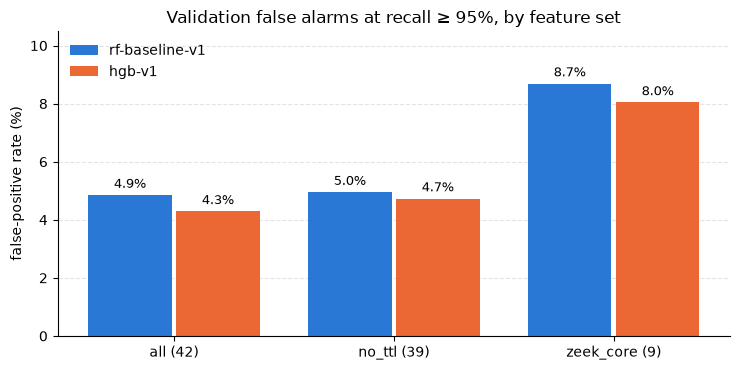

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(FEATURE_SETS))
set_order = list(FEATURE_SETS)

for offset, (model_name, color) in zip((-0.2, 0.2), [("rf-baseline-v1", "#2a78d6"), ("hgb-v1", "#eb6834")]):
    subset = results[results["model"] == model_name].set_index("features").loc[set_order]
    rates = subset["val_fpr"] * 100
    ax.bar(x + offset, rates, width=0.38, color=color, label=model_name)
    for i, rate in enumerate(rates):
        ax.text(i + offset, rate + 0.25, f"{rate:.1f}%", ha="center", fontsize=9)

ax.set(
    xticks=x,
    xticklabels=[f"{k} ({len(FEATURE_SETS[k])})" for k in set_order],
    ylabel="false-positive rate (%)",
    ylim=(0, results["val_fpr"].max() * 100 + 1.8),
    title="Validation false alarms at recall ≥ 95%, by feature set",
)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Key takeaways
- **Dropping TTL (`no_ttl`, 39 features) costs almost nothing:** `hgb-v1` FPR rises only slightly (**4.3% → 4.7%**, +50 false alarms) and `rf-baseline-v1` barely moves (**4.9% → 5.0%**, +11 false alarms). This matches notebook 02's leak-free permutation importance—other features carry the same signal.
- **Using only the 9 `zeek_core` features roughly doubles false alarms:** `hgb-v1` FPR jumps from **4.3% → 8.0%** (480 → 901 false alarms), and `rf-baseline-v1` from **4.9% → 8.7%** (543 → 973).
- **`hgb-v1` beats `rf-baseline-v1` on every feature set** (lower FPR and higher F1).
- **What this points to next:** `zeek_core` leaves out several UNSW features that Zeek *can* compute (such as `rate`, `smean`, `dmean`, and connection-state counts). Testing an expanded Zeek-computable set is the clearest way to recover most of that 8.0% → 4.7% gap while staying compatible with live Zeek logs.